# 05. Capacity model

Goal: build a **battery model** (Wh per volt, solar efficiency, hidden drain, internal resistance) from charge/discharge windows, then **validate** it by predicting the battery voltage over the whole mission.

**Part 1. Analysis:** pick the windows
1. Find candidate nights (one plot)
2. Steady windows: nights with no Starlink (table)
3. Build windows: nights + long Starlink sessions (table)

**Part 2. Models**, in the order we built them
4. **Model A:** joint regression, R fitted with everything else. **A1** = ordinary least squares, **A2** = Huber (robust)
5. **Model B:** R measured on its own, then fixed in the regression. **B1** = ordinary least squares, **B2** = Huber
6. **Model C:** η fixed at 0.95, R fitted. **C1** = OLS, **C2** = Huber
7. **Model D:** η fixed at 0.95, R fixed at the measured value. **D1** = OLS, **D2** = Huber
8. All eight models: parameters side by side, and the model lines on one plot

**Part 3. Prediction**
9. Free-run voltage prediction: all eight models together with the actual voltage

battery1 = battery, battery2 = total load. Load power = battery1 V × battery2 A, so both Starlink and Iridium rows have it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False})

df = pd.read_csv("../data/scout_telemetry_2025-07.csv", na_values="null")
df["t"] = pd.to_datetime(df["created_at"], format="ISO8601", utc=True)
df = df.sort_values("t").reset_index(drop=True)
df["P_load"] = df.voltage_battery1_v * df.current_battery2_a     # W, total load, both links
df["P_solar"] = df.voltage_battery3_v * df.current_battery3_a    # W, Starlink rows only

# Starlink on/off: same rule as nb 03 (messages < 2 min apart = one session, plus 30 s either side)
direct = df[df.communication_mode == "direct"]
session_id = (direct.t.diff() > pd.Timedelta("2min")).cumsum()
sessions = direct.groupby(session_id).t.agg(start="min", end="max").reset_index(drop=True)
df["starlink"] = False
for start, end in sessions.itertuples(index=False):
    df.loc[df.t.between(start - pd.Timedelta("30s"), end + pd.Timedelta("30s")), "starlink"] = True

MODE_NAMES = {0: "MANUAL", 10: "AUTO", 16: "INITIALISING", 17: "mode 17"}
MODE_COLORS = {0: "#9e9e9e", 10: "#2ca02c", 16: "#9467bd", 17: "#d62728"}
LINK_COLORS = {"direct": "#1f77b4", "imt": "#ff7f0e", "globalstar": "#2ca02c"}
MODEL_COLORS = {"A1": "#ff9896", "A2": "#d62728", "B1": "#9e9e9e", "B2": "k",
                "C1": "#aec7e8", "C2": "#1f77b4", "D1": "#98df8a", "D2": "#2ca02c"}
MODEL_STYLES = {"A1": ":", "A2": "-", "B1": "-.", "B2": "--", "C1": ":", "C2": "-", "D1": "-.", "D2": "--"}
START, END = pd.Timestamp("2025-07-14", tz="UTC"), pd.Timestamp("2025-07-31", tz="UTC")

def daily_axis(ax):
    ax.set_xlim(START, END)
    ax.xaxis.set_major_locator(mdates.DayLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

# Part 1. Analysis: pick the windows

## 1. Find candidate nights

**Night = 21:00 to 04:00 UTC.** Check against solar (Starlink rows only): solar is 0 W in every row from 21:00 to 02:59. There are no Starlink rows in the 03:00 hour on any day, and by 04:00 most rows are already above 1 W. The table shows, per UTC hour, the median solar power and the share of rows above 1 W.

In [2]:
s = df.dropna(subset=["P_solar"])
(s.groupby(s.t.dt.hour).P_solar
   .agg(rows="size", median_W="median", share_above_1W=lambda x: (x > 1).mean(), max_W="max")
   .round(2).rename_axis("UTC hour"))

,rows,median_W,share_above_1W,max_W
UTC hour,,,,
0,97,0.00,0.00,0.00
1,263,0.00,0.00,0.00
2,273,0.00,0.00,0.00
4,453,5.64,0.81,36.71
5,409,16.59,0.99,54.75
6,325,32.60,1.00,75.61
7,1497,32.84,0.98,76.98
8,1997,34.98,1.00,116.57
9,3537,61.62,1.00,202.75


**Per-minute data:** battery1 V, load current (battery2 A) and load power are averaged per minute (Starlink rows come 1 s or 15 s apart, Iridium every 2–15 min). Mode is the last one in the minute, and Starlink is on if any part of the minute is inside a session. Minutes with no row stay empty, so the lines break there.

**One panel per night**, from 21:00 on the day shown to 04:00 the next day. Nights 14→15 to 29→30 Jul, **except 25 Jul (reboot)**.
- Black = battery voltage (left axis), red = load power (right axis).
- Blue shading = Starlink on.
- Coloured strip along the bottom = mode.

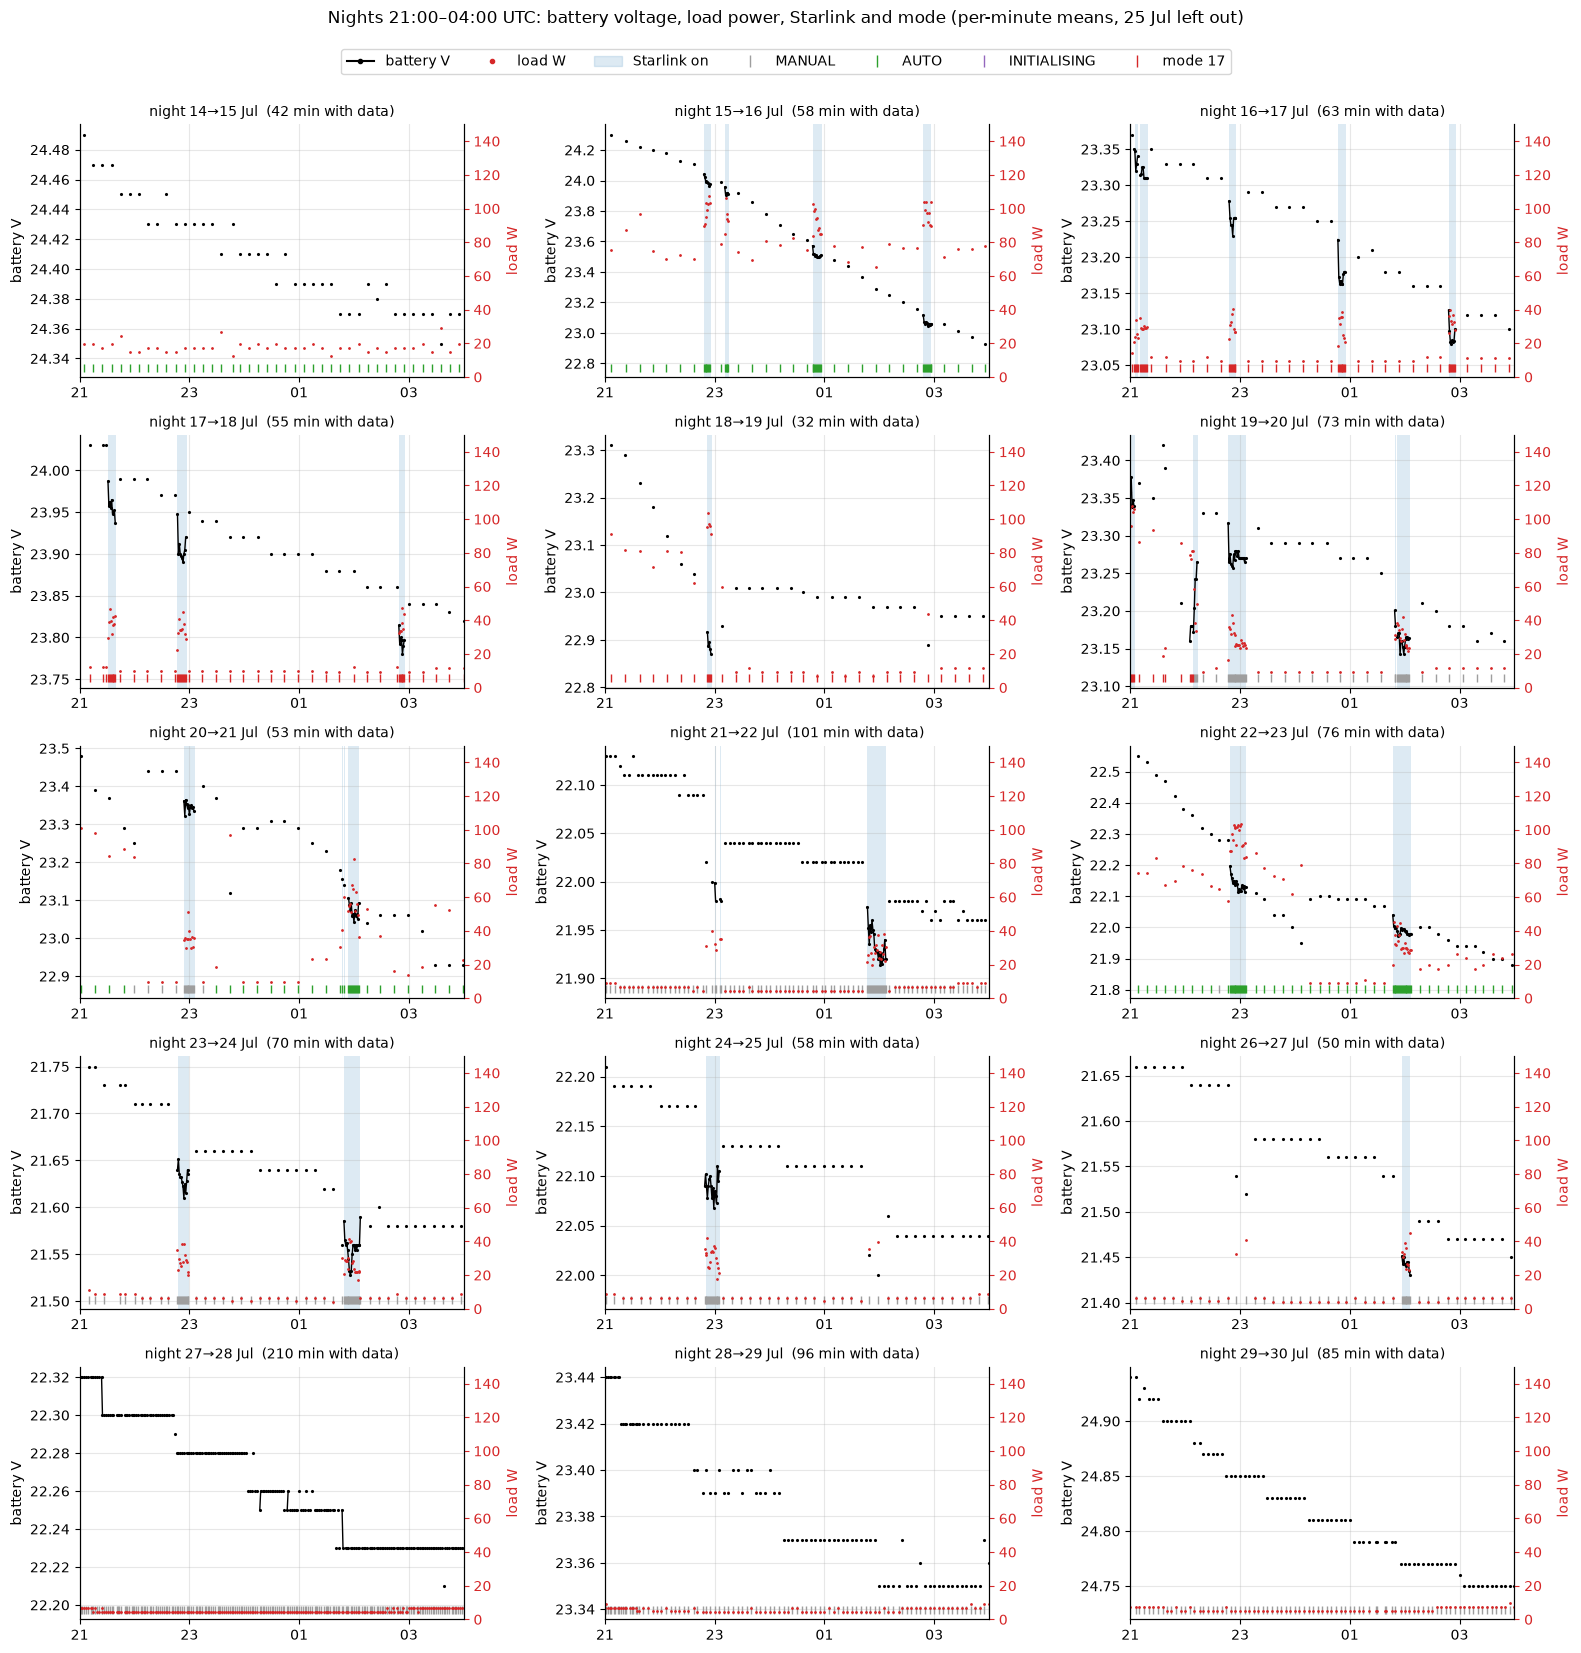

In [3]:
m = (df.set_index("t")
       .resample("1min")
       .agg({"voltage_battery1_v": "mean", "current_battery2_a": "mean", "P_load": "mean",
             "custom_mode": "last", "starlink": "max"}))
m["starlink"] = m.starlink.astype("boolean").fillna(False).astype(bool)

nights = [d for d in pd.date_range("2025-07-14", "2025-07-29", tz="UTC") if d.day != 25]
ncol = 3
nrow = int(np.ceil(len(nights) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(16, 3.2 * nrow))
for ax, day in zip(axes.flat, nights):
    t0, t1 = day + pd.Timedelta("21h"), day + pd.Timedelta("28h")
    n = m.loc[t0:t1]
    # Starlink on: shade each run of on-minutes
    on = n.starlink.values
    edges = np.flatnonzero(np.diff(np.r_[0, on.astype(int), 0]))
    for a, b in zip(edges[::2], edges[1::2]):
        ax.axvspan(n.index[a], n.index[b - 1] + pd.Timedelta("1min"), color="#1f77b4", alpha=0.15, lw=0)
    ax.plot(n.index, n.voltage_battery1_v, ".-", ms=2.5, color="k", lw=1)   # dots so isolated Iridium minutes show
    ax.set_ylabel("battery V")
    ax2 = ax.twinx()
    ax2.plot(n.index, n.P_load, ".", ms=2, color="#d62728")
    ax2.set_ylabel("load W", color="#d62728")
    ax2.tick_params(axis="y", colors="#d62728")
    ax2.set_ylim(0, max(150, n.P_load.max() * 1.05) if n.P_load.notna().any() else 150)
    ax2.grid(False)
    # mode strip at the bottom of the panel
    ylo, yhi = ax.get_ylim()
    strip = ylo - 0.06 * (yhi - ylo)
    for mode, g in n.dropna(subset=["custom_mode"]).groupby("custom_mode"):
        ax.plot(g.index, np.full(len(g), strip), "|", ms=6, color=MODE_COLORS.get(int(mode), "k"))
    ax.set_ylim(strip - 0.04 * (yhi - ylo), yhi)
    ax.set_xlim(t0, t1)
    ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[21, 23, 1, 3]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H"))
    ax.set_title(f"night {day:%d}→{day + pd.Timedelta('1D'):%d %b}  ({n.voltage_battery1_v.notna().sum()} min with data)", fontsize=10)
for ax in axes.flat[len(nights):]:
    ax.set_visible(False)
handles = [plt.Line2D([], [], marker=".", color="k", label="battery V"),
           plt.Line2D([], [], ls="", marker=".", color="#d62728", label="load W"),
           plt.Rectangle((0, 0), 1, 1, color="#1f77b4", alpha=0.15, label="Starlink on")]
handles += [plt.Line2D([], [], ls="", marker="|", ms=8, color=c, label=MODE_NAMES[k]) for k, c in MODE_COLORS.items()]
fig.legend(handles=handles, loc="upper center", ncol=len(handles), bbox_to_anchor=(0.5, 1.01))
fig.suptitle("Nights 21:00–04:00 UTC: battery voltage, load power, Starlink and mode (per-minute means, 25 Jul left out)", y=1.03)
plt.tight_layout()
plt.show()

## 2. Steady windows: nights with no Starlink at all

Only 4 nights have no Starlink session from 21:00 to 04:00: **14→15, 27→28, 28→29 and 29→30 Jul** (Starlink stops for good on 27 Jul 02:05). On those nights the Starlink state can't change, so the window is the whole night. It runs from the first minute with data after 21:00 to the last one before 04:00.

For each window: start/end time, the modes seen (should be one), Starlink state, hours, and load current at the start vs the end. The current is the median over the first and last 10 min of the window, because a single Iridium reading is noisy. Windows where start and end current differ by more than 1 A are flagged.

In [4]:
NO_STARLINK_NIGHTS = ["2025-07-14", "2025-07-27", "2025-07-28", "2025-07-29"]
rows = []
for d in NO_STARLINK_NIGHTS:
    day = pd.Timestamp(d, tz="UTC")
    n = m.loc[day + pd.Timedelta("21h"): day + pd.Timedelta("28h")].dropna(subset=["voltage_battery1_v"])
    start, end = n.index[0], n.index[-1]
    i_start = n.loc[: start + pd.Timedelta("10min"), "current_battery2_a"].median()
    i_end = n.loc[end - pd.Timedelta("10min"):, "current_battery2_a"].median()
    rows.append({
        "night": f"{day:%d}→{day + pd.Timedelta('1D'):%d %b}",
        "start": f"{start:%d %b %H:%M}", "end": f"{end:%d %b %H:%M}",
        "modes": ", ".join(MODE_NAMES.get(int(x), str(x)) for x in sorted(n.custom_mode.dropna().unique())),
        "Starlink": "on" if n.starlink.any() else "off",
        "hours": round((end - start).total_seconds() / 3600, 2),
        "minutes with data": len(n),
        "I start (A)": round(i_start, 2), "I end (A)": round(i_end, 2),
        "flag (ΔI > 1 A)": abs(i_end - i_start) > 1,
    })
windows = pd.DataFrame(rows).set_index("night")
windows

,start,end,modes,Starlink,hours,minutes with data,I start (A),I end (A),flag (ΔI > 1 A)
night,,,,,,,,,
14→15 Jul,14 Jul 21:05,15 Jul 03:55,AUTO,off,6.83,42,0.8,0.7,False
27→28 Jul,27 Jul 21:01,28 Jul 04:00,MANUAL,off,6.98,210,0.3,0.3,False
28→29 Jul,28 Jul 21:00,29 Jul 04:00,MANUAL,off,7.00,96,0.3,0.4,False
29→30 Jul,29 Jul 21:00,30 Jul 04:00,MANUAL,off,7.00,85,0.3,0.3,False


## 3. Build windows: nights + long Starlink sessions

Two kinds of window, each at least 1 h long:
- **Night windows:** 21:00 to 04:00 UTC (solar = 0, checked in step 1), any link. One per night, from the first row after 21:00 to the last row before 04:00. 25 Jul is still left out (reboot).
- **Day windows:** Starlink sessions with no gap over 2 min, lasting at least 1 h. Here solar and battery current are measured the whole time.

Per window:
- **E_solar, E_load (Wh):** trapezoid integral of power over the real row timestamps (all links together, sorted by time). Load = battery1 V × battery2 A. Solar = battery3 V × A, which only exists on Starlink rows, so E_solar = 0 at night.
- **hours:** end − start.
- **ΔV = V_end − V_start** (battery1). Each end is the median of all rows within ±5 min. Sign convention: negative = discharge.
- **ΔI_batt = I_end − I_start** (battery1 A, + = charging), each the median over ±5 min. Only measured on day windows. Night windows get **ΔI = 0** if the mode and Starlink state are the same at both ends, and are **dropped** otherwise (the current would jump and there's no battery current reading to correct for it).
- Mode and Starlink state at each end come from the first and last row with a mode in the window.

In [5]:
def trapz_wh(t, p):
    """Energy in Wh from power p (W) sampled at times t, trapezoid over the real time steps."""
    h = (t - t.iloc[0]).dt.total_seconds().values / 3600
    return float(np.trapezoid(p.values, h)) if len(p) > 1 else 0.0

def end_median(col, at, half=pd.Timedelta("5min")):
    return df.loc[df.t.between(at - half, at + half), col].median()

def window_row(kind, start, end):
    w = df[df.t.between(start, end)]
    load = w.dropna(subset=["P_load"])
    sol = w.dropna(subset=["P_solar"])
    moded = w.dropna(subset=["custom_mode"])
    s_row, e_row = moded.iloc[0], moded.iloc[-1]
    return {
        "kind": kind, "start": start, "end": end,
        "hours": (end - start).total_seconds() / 3600,
        "E_solar": trapz_wh(sol.t, sol.P_solar) if kind == "day" else 0.0,
        "E_load": trapz_wh(load.t, load.P_load),
        "V_start": end_median("voltage_battery1_v", start), "V_end": end_median("voltage_battery1_v", end),
        "I_start": end_median("current_battery1_a", start) if kind == "day" else np.nan,
        "I_end": end_median("current_battery1_a", end) if kind == "day" else np.nan,
        "mode_start": MODE_NAMES.get(int(s_row.custom_mode)), "mode_end": MODE_NAMES.get(int(e_row.custom_mode)),
        "SL_start": bool(s_row.starlink), "SL_end": bool(e_row.starlink),
        "rows": len(w),
    }

rows = []
# night windows
for day in pd.date_range("2025-07-14", "2025-07-29", tz="UTC"):
    if day.day == 25:
        continue
    w = df[df.t.between(day + pd.Timedelta("21h"), day + pd.Timedelta("28h"))].dropna(subset=["voltage_battery1_v"])
    rows.append(window_row("night", w.t.iloc[0], w.t.iloc[-1]))
# day windows: Starlink sessions >= 1 h with no gap > 2 min (same session rule as above)
for start, end in sessions.itertuples(index=False):
    if end - start >= pd.Timedelta("1h"):
        rows.append(window_row("day", start, end))

W = pd.DataFrame(rows)
W["dV"] = W.V_end - W.V_start
W["dI"] = W.I_end - W.I_start
same_state = (W.mode_start == W.mode_end) & (W.SL_start == W.SL_end)
W.loc[(W.kind == "night") & same_state, "dI"] = 0.0
W["use"] = W.dI.notna() & (W.hours >= 1)
W["note"] = np.where(W.use, "", "dropped: night with different mode/Starlink at the ends")

show = W.assign(start=W.start.dt.strftime("%d %b %H:%M"), end=W.end.dt.strftime("%d %b %H:%M"),
                ends=W.mode_start + np.where(W.SL_start, " +SL", "") + " → " + W.mode_end + np.where(W.SL_end, " +SL", ""))
show[["kind", "start", "end", "hours", "E_solar", "E_load", "V_start", "V_end", "dV", "dI", "ends", "rows", "note"]].round(
    {"hours": 2, "E_solar": 1, "E_load": 1, "V_start": 2, "V_end": 2, "dV": 3, "dI": 2})

,kind,start,end,hours,E_solar,E_load,V_start,V_end,dV,dI,ends,rows,note
0,night,14 Jul 21:05,15 Jul 03:55,6.84,0.0,120.6,24.49,24.37,-0.120,0.00,AUTO → AUTO,44,
1,night,15 Jul 21:07,16 Jul 03:56,6.81,0.0,539.2,24.30,22.93,-1.370,0.00,AUTO → AUTO,189,
2,night,16 Jul 21:02,17 Jul 03:54,6.86,0.0,88.3,23.34,23.10,-0.245,0.00,mode 17 → mode 17,222,
3,night,17 Jul 21:11,18 Jul 03:44,6.56,0.0,79.9,24.03,23.83,-0.200,0.00,mode 17 → mode 17,159,
4,night,18 Jul 21:07,19 Jul 03:53,6.75,0.0,217.2,23.31,22.95,-0.360,0.00,mode 17 → mode 17,60,
5,night,19 Jul 21:00,20 Jul 03:49,6.82,0.0,160.4,23.37,23.16,-0.210,NaN,mode 17 +SL → MANUAL,238,dropped: night with different mode/Starlink at...
6,night,20 Jul 21:02,21 Jul 03:59,6.95,0.0,256.0,23.48,22.93,-0.550,0.00,AUTO → AUTO,151,
7,night,21 Jul 21:01,22 Jul 03:56,6.93,0.0,58.6,22.13,21.96,-0.170,0.00,MANUAL → MANUAL,182,
8,night,22 Jul 21:08,23 Jul 03:57,6.82,0.0,295.9,22.55,21.88,-0.670,0.00,AUTO → AUTO,208,
9,night,23 Jul 21:10,24 Jul 03:57,6.77,0.0,61.6,21.75,21.58,-0.170,0.00,MANUAL → MANUAL,174,


# Part 2. Models

All eight models share the same form and the same 22 windows from step 3:

**ΔV = a·E_solar − b·E_load − c·hours + R·ΔI_batt**, no intercept.

- **k = 1/b**: Wh per V (capacity in the linear range)
- **η = a/b**: how much of the solar energy actually reaches the battery
- **c·k (W)**: a constant drain not seen in the load reading (the energy balance in nb 03 gave about 0.9 W)
- **R (Ω)**: internal resistance. It corrects ΔV for the current being different at the two ends.

**Two ways to fit each model:**
- **OLS (A1, B1):** ordinary least squares, every window counts the same. Standard errors from the usual formula.
- **Huber (A2, B2):** iteratively reweighted least squares in numpy (statsmodels/sklearn aren't installed). Windows with residuals above 1.345 × the robust scale (MAD) get weight 1/|r| instead of 1, so one bad window can't pull the fit. Standard errors come from the final weighted fit and are approximate.

For k, η and c·k the standard errors use the delta method.

**Models C and D** fix η = 0.95 instead of fitting it, so a = 0.95·b and the solar and load terms merge into one: **ΔV = b·(0.95·E_solar − E_load) − c·hours + R·ΔI_batt**.

**Sanity targets:** k ≈ 250 Wh/V (Starlink segments, nb claude/07), η 0.9–1.0, R ≈ 0.04 Ω (39 mΩ), c·k ≈ 0.9 W. Anything outside those is flagged.

The helpers below do the fit, the parameter table and the measured-vs-predicted plot for any model.

In [6]:
def huber_irls(X, y, t=1.345, n_iter=100):
    w = np.ones(len(y))
    for _ in range(n_iter):
        sw = np.sqrt(w)
        beta, *_ = np.linalg.lstsq(X * sw[:, None], y * sw, rcond=None)
        r = y - X @ beta
        scale = np.median(np.abs(r - np.median(r))) / 0.6745
        u = np.abs(r) / (t * scale)
        w_new = np.where(u <= 1, 1.0, 1.0 / u)
        if np.allclose(w_new, w, atol=1e-8):
            break
        w = w_new
    p = X.shape[1]
    sigma2 = (w * r ** 2).sum() / (len(y) - p)
    cov = sigma2 * np.linalg.inv(X.T @ (X * w[:, None]))
    return beta, cov, w, r

def check(val, lo, hi):
    return "ok" if lo <= val <= hi else "⚠ outside"

def ols(X, y):
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    r = y - X @ beta
    sigma2 = (r ** 2).sum() / (len(y) - X.shape[1])
    return beta, sigma2 * np.linalg.inv(X.T @ X), np.ones(len(y)), r

def fit_model(X, y, R_fixed=None, robust=True, eta_fixed=None):
    """Fit y = X·beta, Huber if robust else OLS. Returns a dict with the physical parameters.
    eta free:  X = [E_solar, −E_load, −hours (, ΔI)],          beta = [a, b, c (, R)]
    eta fixed: X = [eta·E_solar − E_load, −hours (, ΔI)],      beta = [b, c (, R)]"""
    beta, cov, w, r = huber_irls(X, y) if robust else ols(X, y)
    se = np.sqrt(np.diag(cov))
    if eta_fixed is None:
        a, b, c = beta[:3]; ib, n_core = 1, 3
        pad = lambda g: np.r_[g, np.zeros(len(beta) - 3)]
        g_eta = pad([1 / b, -a / b ** 2, 0]); g_ck = pad([0, -c / b ** 2, 1 / b])
        eta, se_eta, eta_src = a / b, np.sqrt(g_eta @ cov @ g_eta), "fitted"
    else:
        b, c = beta[:2]; ib, n_core = 0, 2
        pad = lambda g: np.r_[g, np.zeros(len(beta) - 2)]
        g_ck = pad([-c / b ** 2, 1 / b])
        eta, se_eta, eta_src = eta_fixed, np.nan, "fixed"
    out = dict(robust=robust, beta=beta, cov=cov, w=w, X=X, y=y, pred=X @ beta,
               k=1 / b, se_k=se[ib] / b ** 2,
               eta=eta, se_eta=se_eta, eta_src=eta_src,
               ck=c / b, se_ck=np.sqrt(g_ck @ cov @ g_ck))
    if R_fixed is None:
        out.update(R=beta[n_core], se_R=se[n_core], R_src="fitted")
    else:
        out.update(R=R_fixed, se_R=np.nan, R_src="fixed")
    return out

def param_table(M):
    rows = [["k (Wh per V)", M["k"], M["se_k"], f"target ≈ 250 → {check(M['k'], 200, 300)}"],
            ["η", M["eta"], M["se_eta"], f"target 0.9–1.0 → {check(M['eta'], 0.9, 1.0)}" if M["eta_src"] == "fitted" else "fixed"],
            ["c·k (W)", M["ck"], M["se_ck"], f"target ≈ 0.9 → {check(M['ck'], 0, 2)}"],
            ["R (mΩ)", M["R"] * 1000, M["se_R"] * 1000, f"target ≈ 40 → {check(M['R'] * 1000, 20, 60)}" if M["R_src"] == "fitted" else "fixed"]]
    t = pd.DataFrame(rows, columns=["parameter", "value", "std error", "sanity"]).set_index("parameter")
    down = M["w"] < 1
    head = f"n = {len(M['y'])} windows ({(U.kind == 'night').sum()} night, {(U.kind == 'day').sum()} day); "
    if M["robust"]:
        print(head + f"Huber, {down.sum()} down-weighted: "
              + ", ".join(f"{s:%d %b %H:%M} (w={x:.2f})" for s, x in zip(U.start[down], M["w"][down])))
    else:
        print(head + "OLS, all windows weight 1")
    return t.style.format({"value": "{:.4g}", "std error": "{:.2g}"})

def fit_plot(M, name, ylabel):
    pred, y, w = M["pred"], M["y"], M["w"]
    fig, ax = plt.subplots(figsize=(8, 7))
    for kind, color in [("night", "#1f3b73"), ("day", "#f2b701")]:
        sel = (U.kind == kind).values
        ax.scatter(pred[sel & (w == 1)], y[sel & (w == 1)], s=45, color=color, edgecolor="k", label=f"{kind} ({sel.sum()})")
        if (sel & (w < 1)).any():
            ax.scatter(pred[sel & (w < 1)], y[sel & (w < 1)], s=45, facecolor="none", edgecolor=color, lw=2,
                       label=f"{kind}, down-weighted ({(sel & (w < 1)).sum()})")
    for xi, yi, s in zip(pred, y, U.start):
        ax.annotate(f"{s:%d %b %H}h", (xi, yi), xytext=(4, 3), textcoords="offset points", fontsize=7, color="grey")
    lim = [min(pred.min(), y.min()) - 0.1, max(pred.max(), y.max()) + 0.1]
    ax.plot(lim, lim, "--", color="grey", lw=1, label="1:1")
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
    ax.set_xlabel(f"predicted {ylabel} (V)"); ax.set_ylabel(f"measured {ylabel} (V)")
    ax.set_title(f"Model {name} ({'Huber' if M['robust'] else 'OLS'}): k = {M['k']:.0f} ± {M['se_k']:.0f} Wh/V, η = {M['eta']:.2f}, "
                 f"η {M['eta_src']}, R = {M['R'] * 1000:.0f} mΩ ({M['R_src']}), c·k = {M['ck']:.1f} W")
    ax.legend(loc="upper left", fontsize=9)
    plt.show()

def model_plot(models, annotate=True, points=True):
    """The model itself: OCV change (ΔV − R·ΔI) vs net energy into the battery (η·E_solar − E_load − P_drain·h).
    Each model is a line through 0 with slope 1/k; dots = windows (open = down-weighted by Huber)."""
    fig, ax = plt.subplots(figsize=(10, 7))
    lo, hi = 0, 0
    for n, M in models.items():
        e_net = (M["eta"] * U.E_solar - U.E_load - M["ck"] * U.hours).values
        d_ocv = (U.dV - M["R"] * U.dI).values
        col = MODEL_COLORS[n]
        for kind, marker in ([("night", "o"), ("day", "s")] if points else []):
            sel = (U.kind == kind).values
            full, down = sel & (M["w"] == 1), sel & (M["w"] < 1)
            ax.scatter(e_net[full], d_ocv[full], marker=marker, s=45, color=col, edgecolor="k", alpha=0.8,
                       label=f"Model {n}, {kind} windows ({sel.sum()})")
            if down.any():
                ax.scatter(e_net[down], d_ocv[down], marker=marker, s=45, facecolor="none", edgecolor=col, lw=2,
                           label=f"Model {n}, {kind}, down-weighted ({down.sum()})")
        if annotate and points:
            for xi, yi, s in zip(e_net, d_ocv, U.start):
                ax.annotate(f"{s:%d %b %H}h", (xi, yi), xytext=(4, 3), textcoords="offset points", fontsize=7, color="grey")
        lo, hi = min(lo, e_net.min()), max(hi, e_net.max())
    x = np.array([lo - 50, hi + 50])
    for n, M in models.items():
        ax.plot(x, x / M["k"], MODEL_STYLES[n], lw=2, color=MODEL_COLORS[n],
                label=f"Model {n} ({'Huber' if M['robust'] else 'OLS'}): ΔOCV = E_net / {M['k']:.0f} Wh/V  (η = {M['eta']:.2f}, P_drain = {M['ck']:.1f} W, R = {M['R'] * 1000:.0f} mΩ)")
    ax.axhline(0, color="grey", lw=0.8); ax.axvline(0, color="grey", lw=0.8)
    ax.set_xlim(x)
    ax.set_xlabel("net energy into battery, E_net = η·E_solar − E_load − P_drain·hours (Wh)")
    ax.set_ylabel("OCV change, ΔV − R·ΔI (V)")
    ax.set_title(f"Battery model: {' vs '.join('Model ' + n for n in models)}")
    ax.legend(loc="upper left", fontsize=8)
    plt.show()

U = W[W.use].reset_index(drop=True)

## 4. Model A: joint regression, R fitted

All four terms are fitted together: **ΔV = a·E_solar − b·E_load − c·hours + R·ΔI_batt**.

In [7]:
X_A = np.column_stack([U.E_solar, -U.E_load, -U.hours, U.dI])
y_A = U.dV.values

### A1: ordinary least squares

In [8]:
A1 = fit_model(X_A, y_A, robust=False)
param_table(A1)

n = 22 windows (14 night, 8 day); OLS, all windows weight 1


,value,std error,sanity
parameter,,,
k (Wh per V),421,26,target ≈ 250 → ⚠ outside
η,1.106,0.054,target 0.9–1.0 → ⚠ outside
c·k (W),-0.2037,1.8,target ≈ 0.9 → ⚠ outside
R (mΩ),76.3,12,target ≈ 40 → ⚠ outside


### A2: Huber

In [9]:
A2 = fit_model(X_A, y_A, robust=True)
param_table(A2)

n = 22 windows (14 night, 8 day); Huber, 2 down-weighted: 14 Jul 21:05 (w=0.59), 18 Jul 21:07 (w=0.62)


,value,std error,sanity
parameter,,,
k (Wh per V),418.7,23,target ≈ 250 → ⚠ outside
η,1.108,0.048,target 0.9–1.0 → ⚠ outside
c·k (W),0.2623,1.6,target ≈ 0.9 → ok
R (mΩ),76.39,11,target ≈ 40 → ⚠ outside


## 5. Model B: R measured on its own, then fixed

### 5a. Internal resistance

Same method as nb claude/07. Over a short window the charge level barely changes, so any voltage wiggle comes from current flowing through R. Within each window, take voltage and current minus their window means. The least-squares slope of ΔV against ΔI (through zero) is R. Starlink rows only (the only ones with battery current), every window size, to check the answer doesn't depend on the window.

In [10]:
g = (df[df.communication_mode == "direct"].set_index("t")[["voltage_battery1_v", "current_battery1_a"]].dropna())
r_rows = []
for f in ["10s", "60s", "300s"]:
    grp = g.groupby(pd.Grouper(freq=f))
    dv = g.voltage_battery1_v - grp.voltage_battery1_v.transform("mean")
    di = g.current_battery1_a - grp.current_battery1_a.transform("mean")
    r_rows.append({"window": f, "R (mΩ)": (dv * di).sum() / (di * di).sum() * 1000, "correlation": np.corrcoef(dv, di)[0, 1]})
r_table = pd.DataFrame(r_rows).set_index("window")
R_FIXED = r_table.loc["60s", "R (mΩ)"] / 1000      # 60 s window, as in nb claude/07
display(r_table.round(3))
print(f"R fixed at {R_FIXED * 1000:.1f} mΩ (60 s window)")

,R (mΩ),correlation
window,,
10s,39.900,0.952
60s,39.207,0.952
300s,40.467,0.957


R fixed at 39.2 mΩ (60 s window)


### 5b. Joint regression with R fixed

R comes from 5a, so its term moves to the left-hand side and isn't fitted:

**ΔV − R·ΔI_batt = a·E_solar − b·E_load − c·hours**

No intercept, same 22 windows. Only the 8 day windows change (the nights have ΔI = 0).

In [11]:
X_B = np.column_stack([U.E_solar, -U.E_load, -U.hours])
y_B = U.dV.values - R_FIXED * U.dI.values

#### B1: ordinary least squares

In [12]:
B1 = fit_model(X_B, y_B, R_fixed=R_FIXED, robust=False)
param_table(B1)

n = 22 windows (14 night, 8 day); OLS, all windows weight 1


,value,std error,sanity
parameter,,,
k (Wh per V),420.3,31,target ≈ 250 → ⚠ outside
η,1.138,0.066,target 0.9–1.0 → ⚠ outside
c·k (W),-0.3118,2.1,target ≈ 0.9 → ⚠ outside
R (mΩ),39.21,nan,fixed


#### B2: Huber

In [13]:
B2 = fit_model(X_B, y_B, R_fixed=R_FIXED, robust=True)
param_table(B2)

n = 22 windows (14 night, 8 day); Huber, 7 down-weighted: 14 Jul 21:05 (w=0.42), 15 Jul 21:07 (w=0.94), 18 Jul 21:07 (w=0.44), 29 Jul 21:00 (w=0.83), 14 Jul 07:43 (w=0.34), 14 Jul 14:04 (w=0.44), 15 Jul 15:31 (w=0.74)


,value,std error,sanity
parameter,,,
k (Wh per V),419.2,23,target ≈ 250 → ⚠ outside
η,1.105,0.058,target 0.9–1.0 → ⚠ outside
c·k (W),0.4125,1.6,target ≈ 0.9 → ok
R (mΩ),39.21,nan,fixed


## 6. Model C: η fixed at 0.95, R fitted

η is fixed instead of fitted (Models A and B gave η ≈ 1.1, which isn't physical). R is fitted with the rest:

**ΔV = b·(0.95·E_solar − E_load) − c·hours + R·ΔI_batt**

In [14]:
ETA_FIXED = 0.95
X_C = np.column_stack([ETA_FIXED * U.E_solar - U.E_load, -U.hours, U.dI])
y_C = U.dV.values

#### C1: ordinary least squares

In [15]:
C1 = fit_model(X_C, y_C, eta_fixed=ETA_FIXED, robust=False)
param_table(C1)

n = 22 windows (14 night, 8 day); OLS, all windows weight 1


,value,std error,sanity
parameter,,,
k (Wh per V),384.8,23,target ≈ 250 → ⚠ outside
η,0.95,nan,fixed
c·k (W),-2.765,1.6,target ≈ 0.9 → ⚠ outside
R (mΩ),84.31,14,target ≈ 40 → ⚠ outside


#### C2: Huber

In [16]:
C2 = fit_model(X_C, y_C, eta_fixed=ETA_FIXED, robust=True)
param_table(C2)

n = 22 windows (14 night, 8 day); Huber, 10 down-weighted: 14 Jul 21:05 (w=0.28), 18 Jul 21:07 (w=0.28), 20 Jul 21:02 (w=0.61), 22 Jul 21:08 (w=0.82), 26 Jul 21:06 (w=0.62), 29 Jul 21:00 (w=0.48), 14 Jul 07:43 (w=0.15), 15 Jul 05:27 (w=0.99), 15 Jul 11:48 (w=0.47), 16 Jul 12:47 (w=0.74)


,value,std error,sanity
parameter,,,
k (Wh per V),400,18,target ≈ 250 → ⚠ outside
η,0.95,nan,fixed
c·k (W),-0.6211,1.3,target ≈ 0.9 → ⚠ outside
R (mΩ),61.58,12,target ≈ 40 → ⚠ outside


## 7. Model D: η fixed at 0.95, R fixed at the measured value

Both η and R are fixed (R from 5a), so only k and the drain are fitted:

**ΔV − R·ΔI_batt = b·(0.95·E_solar − E_load) − c·hours**

In [17]:
X_D = np.column_stack([ETA_FIXED * U.E_solar - U.E_load, -U.hours])
y_D = U.dV.values - R_FIXED * U.dI.values

#### D1: ordinary least squares

In [18]:
D1 = fit_model(X_D, y_D, R_fixed=R_FIXED, eta_fixed=ETA_FIXED, robust=False)
param_table(D1)

n = 22 windows (14 night, 8 day); OLS, all windows weight 1


,value,std error,sanity
parameter,,,
k (Wh per V),375.4,26,target ≈ 250 → ⚠ outside
η,0.95,nan,fixed
c·k (W),-3.487,1.8,target ≈ 0.9 → ⚠ outside
R (mΩ),39.21,nan,fixed


#### D2: Huber

In [19]:
D2 = fit_model(X_D, y_D, R_fixed=R_FIXED, eta_fixed=ETA_FIXED, robust=True)
param_table(D2)

n = 22 windows (14 night, 8 day); Huber, 5 down-weighted: 14 Jul 21:05 (w=0.50), 18 Jul 21:07 (w=0.51), 29 Jul 21:00 (w=0.83), 14 Jul 07:43 (w=0.20), 15 Jul 11:48 (w=0.92)


,value,std error,sanity
parameter,,,
k (Wh per V),408.1,22,target ≈ 250 → ⚠ outside
η,0.95,nan,fixed
c·k (W),-0.5282,1.6,target ≈ 0.9 → ⚠ outside
R (mΩ),39.21,nan,fixed


## 8. All eight models: parameters

In [20]:
MODELS = {"A1": A1, "A2": A2, "B1": B1, "B2": B2, "C1": C1, "C2": C2, "D1": D1, "D2": D2}
fmt = lambda v, s: f"{v:.3g}" if np.isnan(s) else f"{v:.3g} ± {s:.2g}"
pd.DataFrame({f"{n} ({'Huber' if M['robust'] else 'OLS'})": [fmt(M["k"], M["se_k"]), fmt(M["eta"], M["se_eta"]) + (" (fixed)" if M["eta_src"] == "fixed" else ""), fmt(M["ck"], M["se_ck"]),
                             fmt(M["R"] * 1000, M["se_R"] * 1000) + (" (fixed)" if M["R_src"] == "fixed" else "")]
              for n, M in MODELS.items()} | {"target": ["≈ 250", "0.9–1.0", "≈ 0.9", "≈ 40"]},
             index=["k (Wh per V)", "η", "c·k (W)", "R (mΩ)"])

,A1 (OLS),A2 (Huber),B1 (OLS),B2 (Huber),C1 (OLS),C2 (Huber),D1 (OLS),D2 (Huber),target
k (Wh per V),421 ± 26,419 ± 23,420 ± 31,419 ± 23,385 ± 23,400 ± 18,375 ± 26,408 ± 22,≈ 250
η,1.11 ± 0.054,1.11 ± 0.048,1.14 ± 0.066,1.1 ± 0.058,0.95 (fixed),0.95 (fixed),0.95 (fixed),0.95 (fixed),0.9–1.0
c·k (W),-0.204 ± 1.8,0.262 ± 1.6,-0.312 ± 2.1,0.412 ± 1.6,-2.76 ± 1.6,-0.621 ± 1.3,-3.49 ± 1.8,-0.528 ± 1.6,≈ 0.9
R (mΩ),76.3 ± 12,76.4 ± 11,39.2 (fixed),39.2 (fixed),84.3 ± 14,61.6 ± 12,39.2 (fixed),39.2 (fixed),≈ 40


**All eight models on one plot.** x = net energy into the battery over a window, E_net = η·E_solar − E_load − P_drain·hours (Wh, with each model's own η and drain); y = OCV change, ΔV − R·ΔI (V). Each model is a line through 0 with slope 1/k: negative x = discharge (nights), positive = charge. Red = A (η and R fitted), grey/black = B (R fixed), blue = C (η = 0.95, R fitted), green = D (η = 0.95, R fixed); dotted/dash-dot = OLS, solid/dashed = Huber. The windows are left out (they'd appear eight times), only the lines.

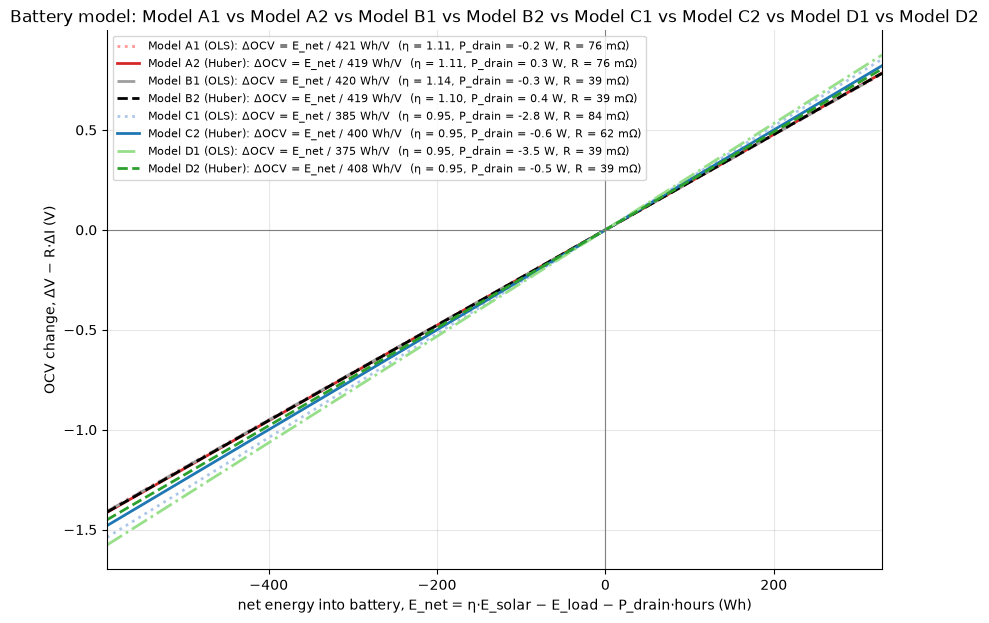

In [21]:
model_plot(MODELS, annotate=False, points=False)

# Part 3. Prediction

## 9. Free-run voltage prediction

**Setup:** every input is known **except battery voltage**. Starting from the first voltage reading, we step the battery forward minute by minute using only:
- **load power** (battery1 V × battery2 A), both links, per-minute mean, linearly interpolated between readings
- **solar power** (battery3 V × A) where Starlink measured it; **between Starlink sessions it's interpolated linearly**, and set to 0 at night (where the solar model from nb 04 is 0). After Starlink stops for good (27 Jul 02:05) there's no solar data at all, so the solar model is used there.

These are exactly the "measured" inputs of nb 06 section 3 (the **both measured** run), so this free run and that one are the same test.
- the parameters of one of the eight models (A1 … D2)

**Battery model:**
- OCV moves with stored energy: **dOCV = (η·P_solar − P_load − P_drain) · dt / k**
- Terminal voltage = **OCV + R · I_batt**, with I_batt = (η·P_solar − P_load − P_drain) / V (+ = charging)
- **Charge cap: the battery doesn't charge above 25.0 V.** On 30 Jul the voltage sits at 24.98–25.00 V from 10:00 to 18:00 UTC. While charging, the current is cut to what keeps the terminal voltage at 25.0 V and the extra solar is lost (curtailed), not stored. Discharge is not affected.

This is a **free run**: the voltage is never corrected along the way, so errors pile up over the 16 days.

Solar model (nb 04): 35.70 − 67.06·cos(ωt) − 9.32·sin(ωt), ω = 2π/24 h, t = UTC hour, clipped at 0. The table shows where each minute's solar comes from.

In [22]:
SOLAR_A, SOLAR_B, SOLAR_C = 35.70, -67.06, -9.32       # nb 04
OMEGA = 2 * np.pi / 24

def solar_model(ts):
    h = (ts - ts.floor("D")).total_seconds() / 3600
    return np.clip(SOLAR_A + SOLAR_B * np.cos(OMEGA * h) + SOLAR_C * np.sin(OMEGA * h), 0, None)

grid = pd.date_range(df.t.iloc[0].floor("min"), df.t.iloc[-1].ceil("min"), freq="1min")
mins = df.set_index("t")[["P_load", "P_solar"]].resample("1min").mean().reindex(grid)
night = solar_model(grid) == 0
last_solar = df.dropna(subset=["P_solar"]).t.max()

inp = pd.DataFrame(index=grid)
inp["P_load"] = mins.P_load.interpolate(method="time").bfill().ffill()
sol = mins.P_solar.copy()
sol[night & sol.isna()] = 0.0                                       # no sun at night
inp["P_solar"] = sol.interpolate(method="time", limit_area="inside")
inp["solar_src"] = np.where(mins.P_solar.notna(), "measured", np.where(night, "night (0)", "interpolated"))
after = inp.index > last_solar                                      # Starlink gone after 27 Jul: no solar data
inp.loc[after, "P_solar"] = solar_model(grid[after])
inp.loc[after, "solar_src"] = "model (no data)"
inp.solar_src.value_counts()

solar_src
interpolated       10083
night (0)           5838
model (no data)     5618
measured            2905
Name: count, dtype: int64

**Run all eight models.** Start: OCV = first measured voltage − R · I_batt at that moment, then step forward one minute at a time. Each forecast is compared with every reported voltage reading (error = actual − forecast).

In [23]:
V_MAX = 25.0

def free_run(M, dt_h=1 / 60):
    k, eta, p_drain, R = M["k"], M["eta"], M["ck"], M["R"]
    n = len(inp)
    V = np.empty(n); OCV = np.empty(n); I_b = np.empty(n)
    P_load, P_sol = inp.P_load.values, inp.P_solar.values
    v_first = df.voltage_battery1_v.dropna().iloc[0]
    V[0] = v_first
    for i in range(n):
        v_now = V[i] if i == 0 else OCV[i] + R * I_b[i - 1]     # terminal V guess, for the battery current
        p_net = eta * P_sol[i] - P_load[i] - p_drain
        I_b[i] = p_net / v_now
        if i == 0:
            OCV[0] = v_first - R * I_b[0]
        V[i] = OCV[i] + R * I_b[i]
        if p_net > 0 and V[i] > V_MAX:          # charge cap: no charging above 25 V, extra solar is lost
            I_b[i] = max((V_MAX - OCV[i]) / R, 0.0)
            V[i] = max(OCV[i] + R * I_b[i], OCV[i])
            p_net = I_b[i] * V[i]
        if i + 1 < n:
            OCV[i + 1] = OCV[i] + p_net * dt_h / k
    return pd.DataFrame({"V_fc": V, "OCV_fc": OCV, "I_batt_fc": I_b}, index=grid)

act = df.dropna(subset=["voltage_battery1_v"])[["t", "communication_mode", "voltage_battery1_v"]].copy()
fc, err = {}, {}
for name, M in MODELS.items():
    fc[name] = free_run(M)
    err[name] = act.voltage_battery1_v - fc[name].V_fc.reindex(act.t.dt.floor("min")).values

display(pd.DataFrame({f"Model {n}": {"mean error (V)": e.mean(), "RMSE (V)": np.sqrt((e ** 2).mean()), "max |error| (V)": e.abs().max()}
                      for n, e in err.items()}).round(2))
day = act.t.dt.floor("D")
daily = pd.concat({f"Model {n}": e.groupby(day).agg(["mean", lambda x: np.sqrt((x ** 2).mean())]).set_axis(["mean error", "RMSE"], axis=1)
                   for n, e in err.items()}, axis=1)
daily.set_axis(daily.index.strftime("%d %b")).round(2).T

,Model A1,Model A2,Model B1,Model B2,Model C1,Model C2,Model D1,Model D2
mean error (V),0.49,0.59,0.19,0.69,1.45,2.01,1.28,2.00
RMSE (V),0.81,0.93,0.47,1.00,2.06,2.79,1.81,2.74
max |error| (V),1.72,2.02,1.88,2.14,4.13,5.48,3.53,5.36


t                    14 Jul  15 Jul  16 Jul  17 Jul  18 Jul  19 Jul  20 Jul  \
Model A1 mean error    0.01    0.15    0.27    0.54    0.86    0.95    1.34   
         RMSE          0.07    0.17    0.29    0.55    0.87    0.96    1.36   
Model A2 mean error    0.02    0.17    0.32    0.62    0.96    1.08    1.49   
         RMSE          0.07    0.20    0.34    0.63    0.97    1.09    1.51   
Model B1 mean error    0.07   -0.01    0.01    0.25    0.49    0.52    0.79   
         RMSE          0.08    0.08    0.10    0.26    0.50    0.53    0.80   
Model B2 mean error    0.11    0.20    0.34    0.67    1.01    1.16    1.54   
         RMSE          0.12    0.21    0.36    0.68    1.01    1.17    1.55   
Model C1 mean error    0.04    0.62    1.17    1.51    1.92    2.28    2.90   
         RMSE          0.11    0.65    1.18    1.51    1.93    2.29    2.91   
Model C2 mean error    0.14    0.82    1.39    1.89    2.43    2.89    3.61   
         RMSE          0.18    0.84    1.41    1.90    2.44    2.90    3.62   
Model D1 mean error    0.09    0.51    1.06    1.38    1.69    2.05    2.57   
         RMSE          0.13    0.53    1.07    1.38    1.69    2.06    2.58   
Model D2 mean error    0.18    0.81    1.34    1.87    2.39    2.85    3.54   
         RMSE          0.21    0.83    1.36    1.88    2.40    2.86    3.55   

t                    21 Jul  22 Jul  23 Jul  24 Jul  25 Jul  26 Jul  27 Jul  \
Model A1 mean error    1.41    1.39    1.10    1.13    1.41    1.45    0.36   
         RMSE          1.41    1.39    1.11    1.15    1.41    1.45    0.71   
Model A2 mean error    1.59    1.59    1.33    1.38    1.68    1.75    0.68   
         RMSE          1.59    1.59    1.33    1.40    1.69    1.75    0.91   
Model B1 mean error    0.81    0.78    0.37    0.37    0.57    0.57   -0.51   
         RMSE          0.81    0.79    0.39    0.41    0.58    0.57    0.82   
Model B2 mean error    1.66    1.72    1.44    1.52    1.81    1.89    0.91   
         RMSE          1.66    1.73    1.44    1.53    1.81    1.89    1.09   
Model C1 mean error    3.20    3.30    3.28    3.36    3.65    3.80    2.74   
         RMSE          3.20    3.30    3.28    3.36    3.66    3.80    2.80   
Model C2 mean error    3.98    4.22    4.29    4.50    4.95    5.20    4.34   
         RMSE          3.98    4.22    4.30    4.51    4.95    5.20    4.37   
Model D1 mean error    2.88    3.00    2.90    2.96    3.16    3.27    2.26   
         RMSE          2.88    3.00    2.90    2.96    3.16    3.28    2.34   
Model D2 mean error    3.89    4.15    4.20    4.42    4.86    5.09    4.32   
         RMSE          3.89    4.15    4.20    4.42    4.86    5.09    4.34   

t                    28 Jul  29 Jul  30 Jul  
Model A1 mean error   -0.66   -0.57   -0.03  
         RMSE          0.77    0.75    0.07  
Model A2 mean error   -0.33   -0.44   -0.03  
         RMSE          0.53    0.56    0.07  
Model B1 mean error   -1.38   -0.71   -0.04  
         RMSE          1.40    0.95    0.08  
Model B2 mean error   -0.04   -0.31   -0.03  
         RMSE          0.39    0.38    0.07  
Model C1 mean error    1.75    1.09    0.26  
         RMSE          1.79    1.11    0.43  
Model C2 mean error    3.54    3.09    1.92  
         RMSE          3.56    3.09    2.08  
Model D1 mean error    1.23    0.45   -0.02  
         RMSE          1.29    0.54    0.07  
Model D2 mean error    3.58    3.16    2.04  
         RMSE          3.59    3.16    2.18

In [24]:
def plot_forecast(names):
    """Actual voltage (dots by link) vs the forecast of each model in `names`; error panel and error-rate panel below."""
    fig, (ax, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 11), sharex=True, gridspec_kw={"height_ratios": [2.2, 1, 1]})
    for link, g in act.groupby("communication_mode"):
        ax.plot(g.t, g.voltage_battery1_v, ".", ms=2, color=LINK_COLORS[link], label=f"actual, {link} ({len(g)})")
    for n in names:
        ax.plot(fc[n].index, fc[n].V_fc, MODEL_STYLES[n] if len(names) > 1 else "-", lw=1.2, color=MODEL_COLORS[n] if len(names) > 1 else "k", label=f"Model {n} forecast (terminal V)")
        if len(names) == 1:
            ax.plot(fc[n].index, fc[n].OCV_fc, "-", lw=0.8, color="grey", alpha=0.7, label=f"Model {n} OCV")
        ax2.plot(act.t, err[n], ".", ms=2, color=MODEL_COLORS[n] if len(names) > 1 else "k",
                 label=f"Model {n}: RMSE {np.sqrt((err[n] ** 2).mean()):.2f} V")
        e_h = pd.Series(err[n].values, index=act.t.values).resample("1h").mean()     # hourly mean error
        ax3.plot(e_h.index, e_h.diff(), MODEL_STYLES[n] if len(names) > 1 else "-", lw=1,
                 color=MODEL_COLORS[n] if len(names) > 1 else "k", label=f"Model {n}")
    ylo = min([act.voltage_battery1_v.min()] + [fc[n].V_fc.min() for n in names]) - 0.3
    for src, col in [("interpolated", "#fde49c"), ("model (no data)", "#f2b701")]:
        sel = inp.solar_src == src
        ax.plot(inp.index[sel], np.full(sel.sum(), ylo), "|", ms=6, color=col, label=f"solar {src}")
    ax.axhline(V_MAX, color="grey", lw=0.8, ls=":")
    ax.set_ylabel("battery V")
    ax.set_title(f"Battery voltage: free-run forecast, {' vs '.join('Model ' + n for n in names)}, vs actual")
    ax.legend(markerscale=4, loc="upper right", fontsize=9)
    ax2.axhline(0, color="grey", lw=0.8)
    ax2.set_ylabel("actual − forecast (V)")
    ax2.legend(markerscale=4, loc="upper right", fontsize=9)
    ax3.axhline(0, color="grey", lw=0.8)
    ax3.set_ylabel("error rate (V per h)")
    ax3.set_title("rate of error change: hour-to-hour change of the hourly mean error (gaps = hours with no reading)", fontsize=10)
    ax3.legend(loc="upper right", fontsize=8, ncol=4)
    daily_axis(ax3)
    plt.tight_layout()
    plt.show()

### 9a. All eight models vs actual

Top: reported voltage (dots, by link) and every model's free-run forecast (same colours and line styles as the model plots in section 8). The strip along the bottom marks where solar is **interpolated** between Starlink sessions (light yellow) or comes from the **model** (dark yellow, after 27 Jul). Middle: error = actual − forecast for each model. Bottom: **rate of error change** in V per hour: the error is averaged per hour, then the change from one hour to the next. Big spikes = hours where a model goes wrong fastest; positive = the actual voltage rises faster than the forecast (or falls slower).

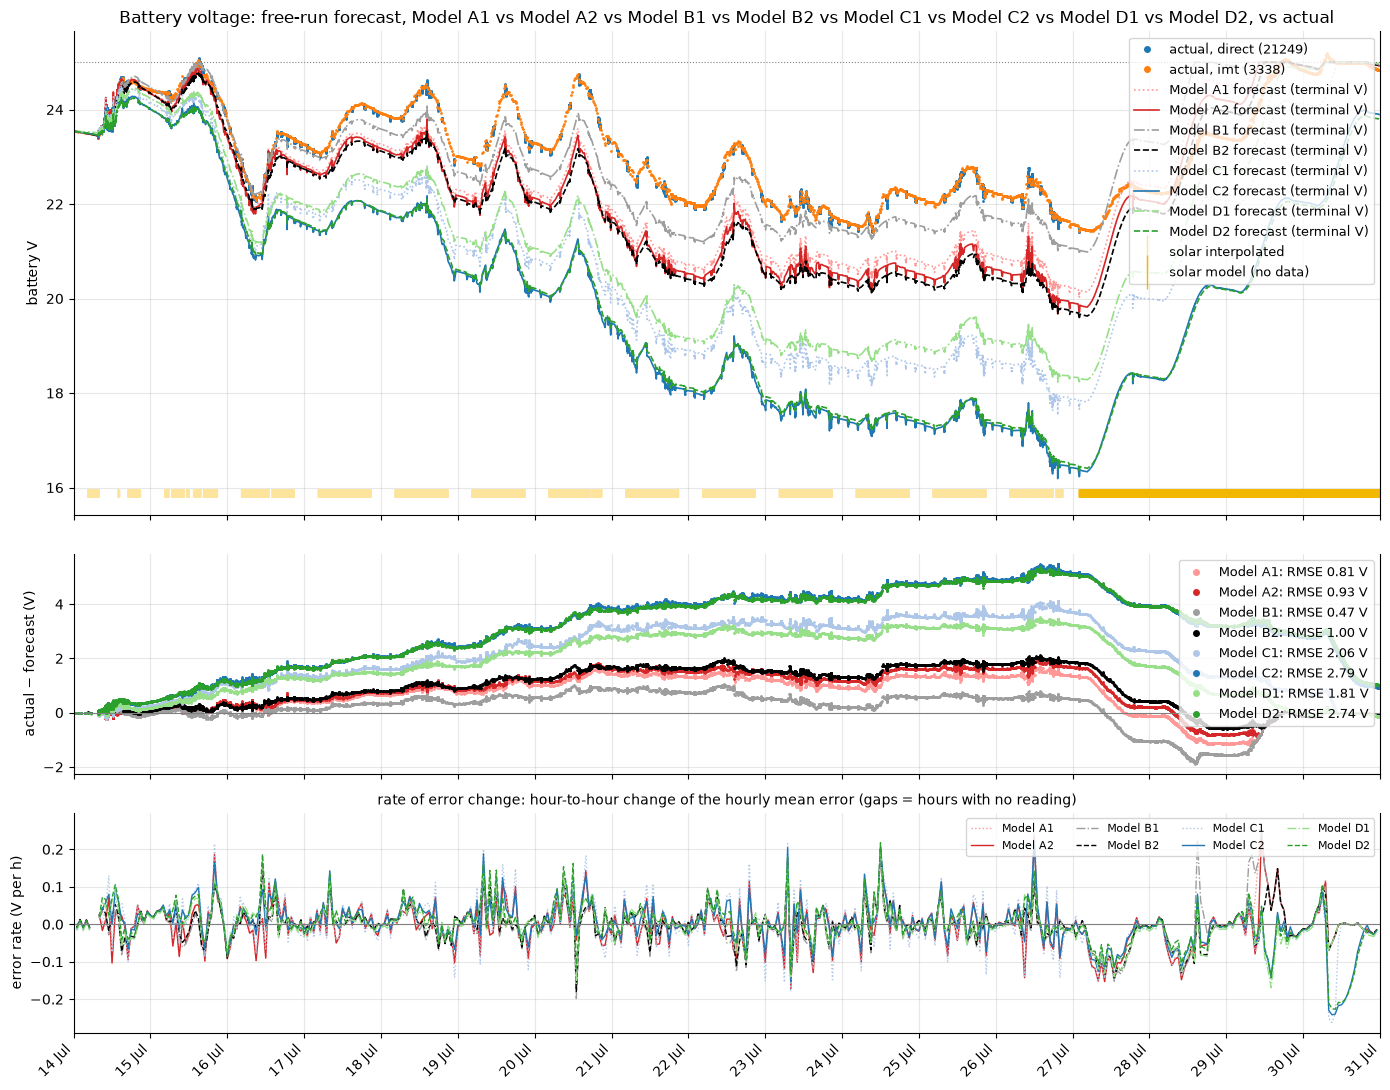

In [25]:
plot_forecast(list(MODELS))

### 9b. Best model on its own

The model with the lowest free-run RMSE in the table above, picked automatically, on the same three panels. The grey line is its OCV (open-circuit voltage, the battery's "charge level" in volts); the black line is the terminal voltage it predicts (OCV + R · I).

best free run: Model B1 (RMSE 0.47 V): k = 420.3 Wh/V, η = 1.138, drain = -0.312 W, R = 39.21 mΩ


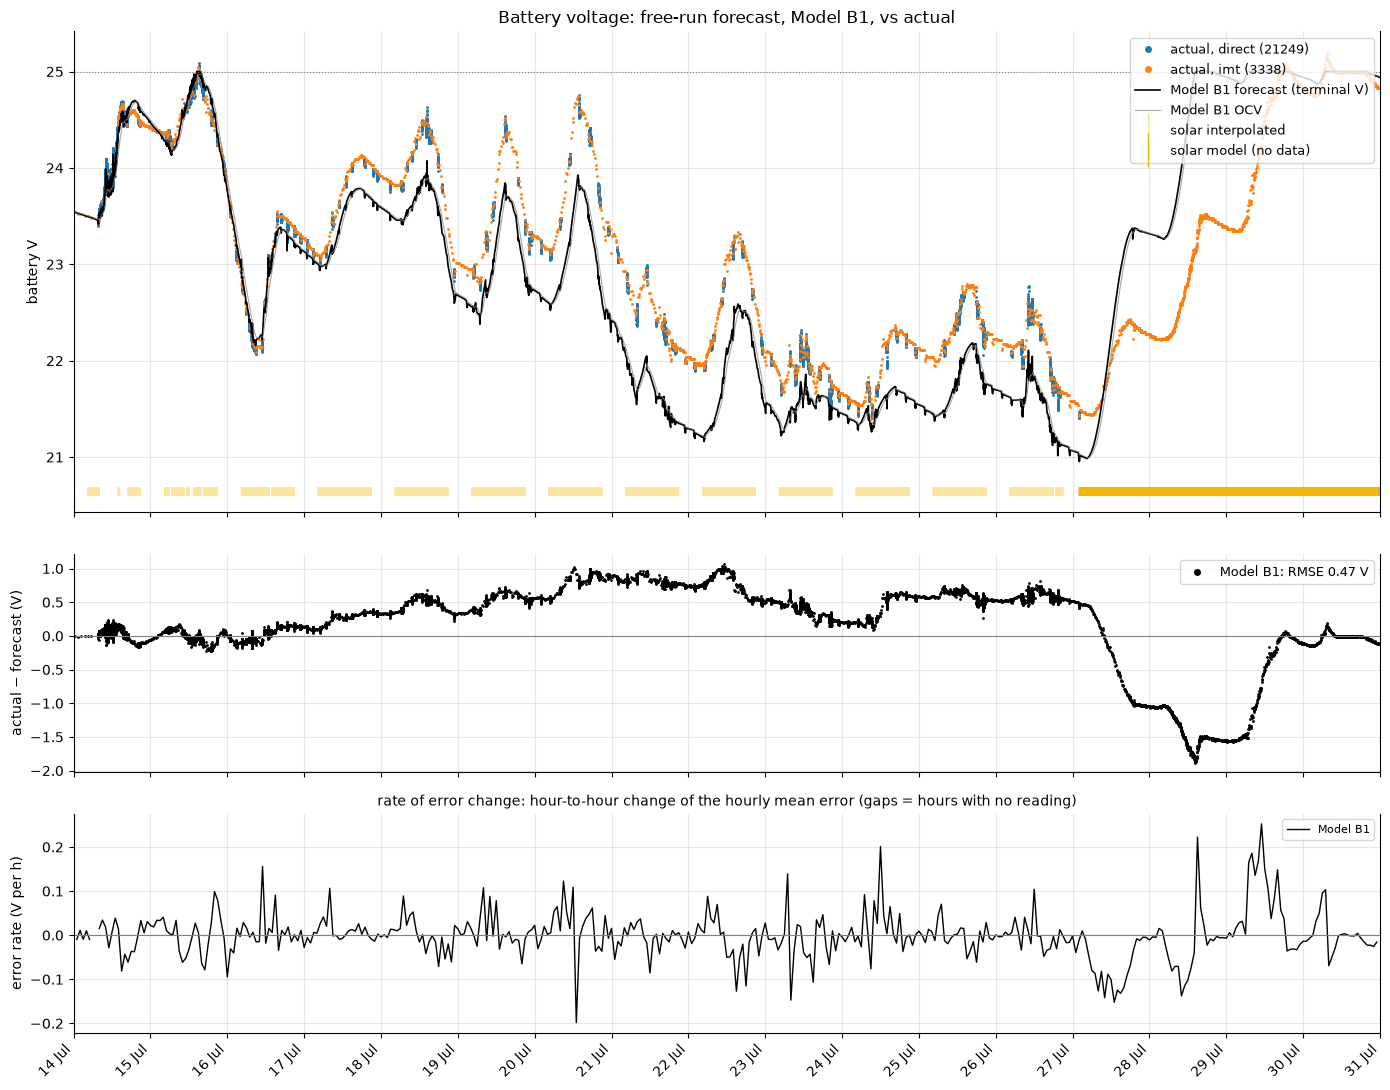

In [26]:
best = min(err, key=lambda n: np.sqrt((err[n] ** 2).mean()))
M = MODELS[best]
print(f"best free run: Model {best} (RMSE {np.sqrt((err[best] ** 2).mean()):.2f} V): "
      f"k = {M['k']:.1f} Wh/V, η = {M['eta']:.3f}, drain = {M['ck']:.3f} W, R = {M['R'] * 1000:.2f} mΩ")
plot_forecast([best])